# A/B Testing Case Study: Landing Page Call-to-Action Button

> **TL;DR:** I tested "Enroll Now" against "Secure Free Trial" on 5,600 simulated visitors over 2 weeks. "Enroll Now" raised click-through rate from 15.5% to 19.6% (+4.1pp, p < 0.001, 95% CI 2.1–6.1pp), which clears the 3pp bar agreed before launch. **Recommendation: ship**, then keep monitoring CTR and downstream conversion after rollout.

This notebook walks through a complete A/B test in two stages:

- **Part 1: Experiment Design (pre-data).** Business and statistical hypotheses, the primary metric, the randomization unit, a power analysis to size the test, and how the data would be collected in a real organization.
- **Part 2: Results Analysis (post-data).** Choosing and justifying a statistical test, checking statistical and practical significance, and making a ship / don't-ship call.

**A note on the data:** no real experiment was run. The dataset (`ab_test_click_data.csv`) is simulated at the end of Part 1 to match the design. The goal is to show the process, not to claim a real product result.

**Skills shown:** power analysis, experiment design, data validation, statistical test selection, confidence intervals, and turning a result into a business decision.

## Part 1: Experiment Design

> At this point **no data exists yet**. Everything below is scoped the way it would be before an experiment launches: business framing, hypotheses, metric selection, sample size, and the data collection process.

### Business Context

![diagram](control_experimental.png)

A mid-sized SaaS company's landing page currently uses a **Secure Free Trial** button (the **Control** version). The growth team has proposed a new **Enroll Now** button (the **Experimental** version), hypothesizing that more action-oriented language will drive more clicks. Users are randomly split between the two versions when they land on the page; those who see the existing button are the **control group**, and those who see the new button are the **experimental group**.

The business question: **should the company replace the existing button with the new one?**

### Primary Metric (Overall Evaluation Criterion)

I use **Click-Through Rate (CTR)**, the proportion of users who click the button, as the primary metric (OEC). CTR is a standard, well-understood engagement metric, is directly attributable to the button change (nothing else on the page differs between arms), and can be measured over a short window, making it well suited to this test.

### Business Hypothesis

**The growth team's hypothesis: the "Enroll Now" button will increase CTR by at least 3 percentage points, from a baseline of ≈15% to ≈18%** (a 20% relative lift). This absolute gap is the **Minimum Detectable Effect (MDE)**: the smallest improvement, decided upfront rather than after seeing results, that would actually be worth the engineering cost and risk of a full rollout.

### Decision Rule

Agreed before launch: **ship if the lift is statistically significant (p < 0.05) and the observed lift is at least the MDE (3pp).**

The MDE does two jobs here: it's the effect size the test is powered to detect, and it's the practical-significance bar for shipping. I also report the 95% confidence interval, so stakeholders can see how certain it is that the true lift clears 3pp, not just whether the point estimate does.

### Statistical Hypothesis

In plain terms: the **null hypothesis** is that the new button makes no real difference to CTR, and any observed gap is just noise. The **alternative hypothesis** is that the two buttons' true CTRs are actually different. Formally, letting $p_{con}$ and $p_{exp}$ denote the true (population) click-through rates for the control and experimental groups:

$$
\begin{cases}
H_0 : p_{con} = p_{exp} \\
H_1 : p_{con} \neq p_{exp}
\end{cases}
$$

A **two-sided test** is used because, in principle, the new button could perform worse than the old one, and I don't want to rule that out in advance.

### Randomization Unit & Data Requirements

The **unit of randomization is the `user_id`**: each unique visitor is randomly assigned to either the control or experimental arm the first time they land on the page, and stays in that arm for the duration of the test (a "sticky" assignment). This is the natural choice here because the question is about individual click behavior, not session- or page-view-level behavior, and randomizing at the session level would let the same user see both variants, contaminating the comparison.

Key design assumptions (SUTVA, the Stable Unit Treatment Value Assumption):
- One user's assignment and behavior doesn't affect another user's outcome (no network/social interference).
- A user is exposed to exactly one variant for the full test duration.

**Data required per user, at minimum:**

| Field | Description |
|---|---|
| `user_id` | Unique visitor identifier |
| `group` | Assigned arm (`con` / `exp`) |
| `click` | Whether the button was clicked (1/0) |
| `timestamp` | When the event occurred |

### Data Collection Process

Before this test could actually run, a few things would need to happen. For a portfolio project this is simulated, but in practice this stage takes real coordination:

- **Stakeholder alignment.** Product and growth leadership agree on CTR as the OEC, sign off on the 3pp absolute MDE (20% relative) as the bar for a "worthwhile" launch, and agree on the decision rule above.
- **Engineering collaboration.** Front-end/engineering implement the button variant and wire up click-event logging to the analytics pipeline; an experiment-assignment service (or feature-flagging tool) handles the actual traffic split and guarantees sticky, mutually-exclusive assignment with any other concurrently running experiments.
- **QA / pre-launch checks.** Before trusting any results, teams commonly run an **A/A test** (splitting traffic but showing everyone the same button) to confirm the randomization and logging pipeline are unbiased, and confirm the two arms differ *only* in button copy, with no other change shipping alongside it.
- **Data ownership.** Data engineering agrees on the event schema (the four fields above) and owns the pipeline that lands raw events into a queryable table. The simulated dataset below is built to match this schema.
- **Monitoring while live.** The team watches for **Sample Ratio Mismatch (SRM)**, an uneven group split that signals broken randomization, and for guardrail metrics like page load time. Neither is used to stop the test early based on the primary metric (see "peek and stop" in the Conclusion).

### Sample Size & Test Duration: Power Analysis

Before launch, I need to decide how many users to include in each arm. This is determined through **power analysis**, which depends on:

- **Significance level ($\alpha$):** probability of a Type I error (false positive). Industry-standard **5%**.
- **Power ($1-\beta$):** probability of detecting a true effect if one exists. Industry-standard **80%**, i.e. a 20% Type II error rate ($\beta$).
- **Effect size:** derived from the two absolute proportions being compared: baseline CTR (15%) and target CTR (18%), i.e. the same 3pp absolute MDE introduced above (20% relative), expressed the way the sample-size formula actually consumes it, since `proportion_effectsize` takes two proportions, not a relative percentage.

Too small a sample risks missing a real effect; too large wastes time and exposes more users to an unproven change than necessary.

In [1]:
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.stats.api as sms
from matplotlib.ticker import PercentFormatter
from scipy.stats import chisquare, norm
from statsmodels.stats.proportion import proportions_ztest

%matplotlib inline

In [2]:
# Design parameters, agreed with stakeholders before the test is run
alpha = 0.05          # significance level
power = 0.80          # desired power (1 - beta)

p_con_baseline = 0.15       # current CTR of the "Secure Free Trial" button
mde_relative = 0.20         # target relative lift; sets the 3pp absolute MDE below
p_exp_target = p_con_baseline * (1 + mde_relative)   # target CTR of "Enroll Now"
mde_absolute = p_exp_target - p_con_baseline

print(f"Baseline CTR (control):        {p_con_baseline:.1%}")
print(f"Target CTR (experimental):     {p_exp_target:.1%}")
print(f"Minimum Detectable Effect:     {mde_absolute:.1%} absolute (≈{mde_relative:.0%} relative)")

# Effect size for two independent proportions. Cohen's h comes out negative because the
# baseline is passed first; only its size matters for the sample-size calculation.
effect_size = sms.proportion_effectsize(p_con_baseline, p_exp_target)
print(f"\nEffect size (Cohen's h): {abs(effect_size):.4f}")

# Required sample size per group, assuming equal-sized arms
required_n = sms.NormalIndPower().solve_power(
    effect_size,
    power=power,
    alpha=alpha,
    ratio=1,
)
required_n = ceil(required_n)

print(f"Required sample size per group: {required_n:,}")
print(f"Total required sample size:     {required_n * 2:,}")

Baseline CTR (control):        15.0%
Target CTR (experimental):     18.0%
Minimum Detectable Effect:     3.0% absolute (≈20% relative)

Effect size (Cohen's h): 0.0809
Required sample size per group: 2,399
Total required sample size:     4,798


**Translating sample size into test duration.** Sample size alone doesn't say how long the test needs to run. That depends on how much traffic the landing page actually gets. Suppose analytics reports the page averages **400 unique visitors/day**, split 50/50 across the two arms (200/day per arm). I then round up to whole weeks, so every day of the week appears equally often (weekday and weekend visitors can behave differently).

In [3]:
# Traffic assumption, agreed with the analytics team
daily_visitors_per_group = 200

min_duration_days = ceil(required_n / daily_visitors_per_group)
# Round up to whole weeks so day-of-week effects are balanced
test_duration_days = ceil(min_duration_days / 7) * 7

print(f"Assumed traffic per group: {daily_visitors_per_group}/day")
print(f"Minimum duration:          {min_duration_days} days")
print(f"Planned duration:          {test_duration_days} days ({test_duration_days // 7} full weeks)")

Assumed traffic per group: 200/day
Minimum duration:          12 days
Planned duration:          14 days (2 full weeks)


### From Design to Data

In a real organization, the test would now run for the planned duration while engineering logs click events to the agreed schema.

**Since no real experiment was run for this project, I simulate the outcome of this exact design**: the planned duration, the assumed traffic and the same schema. Each visitor arrives at a random time during the test and is assigned to an arm by a 50/50 coin flip, so group sizes vary slightly, as they would in a real test. The true experimental CTR is set modestly above the target (18% target → 19% simulated true rate) rather than exactly on the MDE boundary.

In [4]:
np.random.seed(42)

n_total = test_duration_days * daily_visitors_per_group * 2

# True click probabilities used to simulate the outcome. The experimental CTR is set
# slightly above the 18% target (19% true rate), a plausible case where the change beats
# the minimum bar. Setting it exactly at the MDE would make the decision rule
# (observed lift >= MDE) a coin flip driven by sampling noise alone.
p_click_con_true = p_con_baseline
p_click_exp_true = p_exp_target + 0.01

# Each visitor arrives at a random time during the test and is assigned by a 50/50 coin flip
arrival_seconds = np.sort(np.random.uniform(0, test_duration_days * 24 * 3600, size=n_total))
timestamps = pd.Timestamp("2024-01-01") + pd.to_timedelta(arrival_seconds, unit="s")
groups = np.where(np.random.binomial(1, 0.5, size=n_total) == 1, 'exp', 'con')
p_click = np.where(groups == 'exp', p_click_exp_true, p_click_con_true)
clicks = np.random.binomial(1, p_click)

df_ab_test = pd.DataFrame({
    'user_id': np.arange(1, n_total + 1),
    'group': groups,
    'click': clicks,
    'timestamp': timestamps.floor('s'),
})

df_ab_test.to_csv('ab_test_click_data.csv', index=False)

print(f"Simulated {n_total:,} users over {test_duration_days} days")
print(df_ab_test['group'].value_counts().to_string())
df_ab_test.head()

Simulated 5,600 users over 14 days
group
con    2844
exp    2756


,user_id,group,click,timestamp
0,1,con,0,2024-01-01 00:00:14
1,2,con,0,2024-01-01 00:00:37
2,3,con,0,2024-01-01 00:02:42
3,4,exp,0,2024-01-01 00:04:34
4,5,con,1,2024-01-01 00:12:03


### Data Cleaning & Sanity Checks

Before analyzing results, an analyst would run the same validation checks on real exported data that I run here. This is the practical follow-through on the "QA / monitoring" points raised in the Data Collection Process section.

Because the data is simulated, the missing-value, duplicate and assignment checks pass by construction here. They're included because on real data that's where problems show up. The SRM check is a real test, since group sizes come from random assignment.

In [5]:
# 1. Missing values
print("Missing values per column:")
print(df_ab_test.isna().sum())

# 2. Duplicate users (a user should appear exactly once)
duplicate_users = df_ab_test['user_id'].duplicated().sum()
print(f"\nDuplicate user_id rows: {duplicate_users}")

# 3. Every user assigned to exactly one group (mutually exclusive assignment)
users_per_group_count = df_ab_test.groupby('user_id')['group'].nunique()
multi_group_users = (users_per_group_count > 1).sum()
print(f"Users assigned to more than one group: {multi_group_users}")

# 4. Sample Ratio Mismatch (SRM) check: observed split vs. intended 50/50 split
#
# H0: users were assigned con/exp in a true 50/50 split (randomization is healthy)
# H1: the split differs from 50/50 by more than chance (randomization/logging is broken)
#
# alpha = 0.01 here (stricter than the 0.05 used for the CTR test later), since this
# check effectively runs on every experiment and a looser threshold would trigger false
# alarms on ~1-in-20 healthy tests.
group_counts = df_ab_test['group'].value_counts()
expected_counts = [group_counts.sum() / 2, group_counts.sum() / 2]
srm_chi2, srm_p_value = chisquare(group_counts, f_exp=expected_counts)

srm_alpha = 0.01
print(f"\nObserved group split: con={group_counts['con']:,}, exp={group_counts['exp']:,}")
print(f"SRM chi-square p-value: {srm_p_value:.3f} vs. alpha: {srm_alpha}")
print("Fail to reject H0 -> SRM check passed: no evidence the randomization pipeline is broken."
      if srm_p_value > srm_alpha else
      "Reject H0 -> SRM check FAILED: split deviates from 50/50 more than chance would explain. Investigate the assignment pipeline before trusting results.")

print(f"\nDataset shape: {df_ab_test.shape}")
print(f"Date range: {df_ab_test['timestamp'].min()} to {df_ab_test['timestamp'].max()}")

Missing values per column:
user_id      0
group        0
click        0
timestamp    0
dtype: int64

Duplicate user_id rows: 0
Users assigned to more than one group: 0

Observed group split: con=2,844, exp=2,756
SRM chi-square p-value: 0.240 vs. alpha: 0.01
Fail to reject H0 -> SRM check passed: no evidence the randomization pipeline is broken.

Dataset shape: (5600, 4)
Date range: 2024-01-01 00:00:14 to 2024-01-14 23:54:18


### Data Description

With the data validated, here's a quick look at the data before moving into formal analysis in Part 2.

In [6]:
summary = df_ab_test.groupby('group').agg(
    user_count=('user_id', 'count'),
    total_clicks=('click', 'sum'),
    ctr=('click', 'mean'),
)
summary

,user_count,total_clicks,ctr
group,,,
con,2844,440,0.154712
exp,2756,540,0.195936


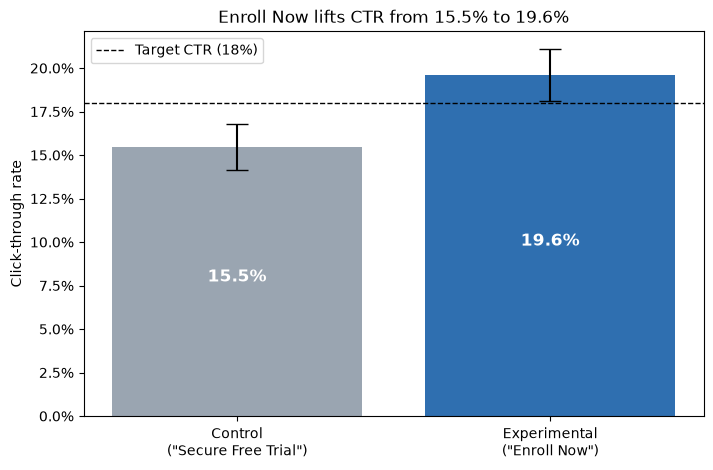

In [7]:
# 95% CI for each group's CTR, shown as error bars
ci_half_width = norm.ppf(0.975) * np.sqrt(summary['ctr'] * (1 - summary['ctr']) / summary['user_count'])

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(['Control\n("Secure Free Trial")', 'Experimental\n("Enroll Now")'], summary['ctr'],
       yerr=ci_half_width, capsize=8, color=['#9aa5b1', '#2f6fb0'])
ax.axhline(p_exp_target, color='black', linestyle='--', linewidth=1, label=f'Target CTR ({p_exp_target:.0%})')
for i, ctr in enumerate(summary['ctr']):
    ax.text(i, ctr / 2, f'{ctr:.1%}', ha='center', color='white', fontweight='bold', fontsize=12)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel('Click-through rate')
ax.set_title(f"Enroll Now lifts CTR from {summary.loc['con', 'ctr']:.1%} to {summary.loc['exp', 'ctr']:.1%}")
ax.legend(loc='upper left')

plt.savefig('ctr_by_group.png', dpi=300, bbox_inches='tight')
plt.show()

The experimental group ("Enroll Now") shows a higher observed CTR (19.6%) than the control group ("Secure Free Trial", 15.5%), above the 18% target. Next, I test whether the gap is statistically and practically significant.

## Part 2: Results Analysis

With the experiment data collected and validated, next comes the analysis phase: choosing the right statistical test, checking significance, and translating the result into a business decision.

**Recap of the hypotheses:**

$$
\begin{cases}
H_0 : p_{con} = p_{exp} \\
H_1 : p_{con} \neq p_{exp}
\end{cases}
\qquad \alpha = 0.05 \qquad \text{MDE} = 3\text{pp absolute} \ (\approx 20\% \text{ relative})
$$

### Choosing the Right Statistical Test

CTR is a **binary outcome** (click / no click) aggregated into a **proportion** per group, which narrows down the reasonable options considerably:

| Test | When it applies | Applicable here? |
|---|---|---|
| **Two-sample z-test for proportions** | Comparing two independent proportions/rates, large sample size | ✅ Yes: this is exactly the setup here |
| **Two-sample t-test** | Comparing means of a *continuous* variable across two groups | ❌ CTR is binary, not continuous. Would apply if comparing e.g. average time-on-page instead |
| **Chi-square test of independence** | Testing association between two categorical variables (e.g. group × click) | ⚠️ Would give an equivalent result to the two-sided z-test here (chi-square with 1 dof is mathematically equivalent to a two-sided z-test on two proportions), but the z-test is preferred because it directly yields a signed effect size, a confidence interval on the *difference*, and supports one-sided tests |
| **Mann-Whitney U / non-parametric tests** | Comparing distributions of a continuous/ordinal variable when normality doesn't hold | ❌ Not applicable to a binary outcome; useful for secondary numeric metrics (e.g. session duration) that are skewed |

**Why the z-test is valid here, via the Central Limit Theorem:** each group's click outcomes are i.i.d. Bernoulli trials. By the CLT, the sample proportion $\hat{p}$ is approximately normally distributed once the sample size is reasonably large. The standard rule of thumb is $np \geq 10$ and $n(1-p) \geq 10$ for both groups. I check that below rather than just asserting it.

Unlike a continuous metric, a binary proportion doesn't need (or have) a meaningful normality/variance check on the raw data itself (Shapiro-Wilk, Levene's test, etc. are built for continuous variables). Those checks matter when the *outcome itself* is numeric and skewed (e.g. revenue, time-on-page). It's worth knowing when to reach for them, and when they're the wrong tool, as here.

In [8]:
# Check the CLT rule-of-thumb (np >= 10 and n(1-p) >= 10) for both groups
for grp in ['con', 'exp']:
    n_grp = (df_ab_test['group'] == grp).sum()
    p_grp = df_ab_test.loc[df_ab_test['group'] == grp, 'click'].mean()
    np_check = n_grp * p_grp
    n1p_check = n_grp * (1 - p_grp)
    print(f"Group '{grp}': n={n_grp:,}, p={p_grp:.3f} -> n*p={np_check:.0f}, n*(1-p)={n1p_check:.0f} "
          f"({'OK' if np_check >= 10 and n1p_check >= 10 else 'FAILS rule of thumb'})")

Group 'con': n=2,844, p=0.155 -> n*p=440, n*(1-p)=2404 (OK)
Group 'exp': n=2,756, p=0.196 -> n*p=540, n*(1-p)=2216 (OK)


Both groups clear the $np \geq 10$ and $n(1-p) \geq 10$ rule of thumb, so the normal approximation holds and the two-sample z-test for proportions applies.

### Statistical Significance Test

Below: the pooled proportion (assuming $H_0$ is true), its standard error, the z-statistic and the resulting p-value.

In [9]:
# Observed counts, from the summary table above
x_con, x_exp = summary.loc[['con', 'exp'], 'total_clicks'].tolist()
n_con, n_exp = summary.loc[['con', 'exp'], 'user_count'].tolist()

# Sample proportions
p_con_hat = x_con / n_con
p_exp_hat = x_exp / n_exp

# Pooled proportion (under H0: p_con = p_exp)
p_pooled_hat = (x_con + x_exp) / (n_con + n_exp)

# Pooled standard error, used for the test statistic because it assumes H0 is true
se_pooled = np.sqrt(p_pooled_hat * (1 - p_pooled_hat) * (1 / n_con + 1 / n_exp))

# Test statistic and two-sided p-value
z_stat = (p_exp_hat - p_con_hat) / se_pooled
z_crit = float(norm.ppf(1 - alpha / 2))
p_value = float(2 * norm.sf(abs(z_stat)))

print(f"Control CTR:        {p_con_hat:.4f}")
print(f"Experimental CTR:   {p_exp_hat:.4f}")
print(f"Pooled CTR:         {p_pooled_hat:.4f}")
print(f"Standard error:     {se_pooled:.5f}")
print(f"Z-statistic:        {z_stat:.3f}")
print(f"Z-critical (95%):   {z_crit:.3f}")
print(f"P-value:            {p_value:.4g}")

Control CTR:        0.1547
Experimental CTR:   0.1959
Pooled CTR:         0.1750
Standard error:     0.01016
Z-statistic:        4.059
Z-critical (95%):   1.960
P-value:            4.928e-05


**Note:** the z-test above is computed manually (pooled proportion → SE → z-statistic) to make the mechanics explicit. In practice, `statsmodels.stats.proportion.proportions_ztest` performs the same pooled-proportion z-test in one call, and the next cell checks that it agrees with the manual result.

In [10]:
z_stat_sm, p_value_sm = proportions_ztest([x_exp, x_con], [n_exp, n_con])

print(f"statsmodels z-statistic: {z_stat_sm:.3f} (manual: {z_stat:.3f})")
print(f"statsmodels p-value:     {p_value_sm:.4g} (manual: {p_value:.4g})")

statsmodels z-statistic: 4.059 (manual: 4.059)
statsmodels p-value:     4.928e-05 (manual: 4.928e-05)


#### Checking Statistical Significance

With the z-statistic and p-value computed above, I compare the p-value against $\alpha = 0.05$ to decide whether to reject $H_0$.

In [11]:
is_significant = p_value <= alpha

print(f"P-value: {p_value:.4g} vs. alpha: {alpha}")
print("Reject H0: the 'Enroll Now' button's CTR differs from the 'Secure Free Trial' button's."
      if is_significant else
      "Fail to reject H0: not enough evidence that the two buttons' CTRs differ.")

P-value: 4.928e-05 vs. alpha: 0.05
Reject H0: the 'Enroll Now' button's CTR differs from the 'Secure Free Trial' button's.


#### Visualizing the Test Statistic vs. the Rejection Region

To make the decision above intuitive, the plot below shows the standard normal distribution with the two-sided rejection region shaded, and where the observed z-statistic falls.

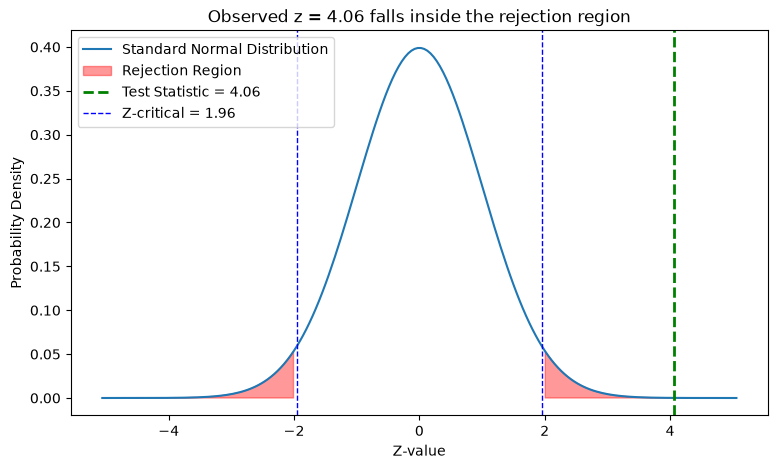

In [12]:
x_max = max(4, abs(z_stat) + 1)
x = np.linspace(-x_max, x_max, 200)
y = norm.pdf(x)

plt.figure(figsize=(9, 5))
plt.plot(x, y, label='Standard Normal Distribution')
plt.fill_between(x, y, where=(x > z_crit) | (x < -z_crit), color='red', alpha=0.4, label='Rejection Region')
plt.axvline(z_stat, color='green', linestyle='dashed', linewidth=2, label=f'Test Statistic = {z_stat:.2f}')
plt.axvline(z_crit, color='blue', linestyle='dashed', linewidth=1, label=f'Z-critical = {z_crit:.2f}')
plt.axvline(-z_crit, color='blue', linestyle='dashed', linewidth=1)
plt.xlabel('Z-value')
plt.ylabel('Probability Density')
plt.title(f"Observed z = {z_stat:.2f} falls {'inside' if abs(z_stat) > z_crit else 'outside'} the rejection region")
plt.legend()
plt.show()

The test statistic (z ≈ 4.06, green dashed line) falls well inside the red rejection region, past the critical values (±1.96), which confirms the decision to reject $H_0$.

### Confidence Interval & Practical Significance

Statistical significance only says the lift is probably above zero. To decide whether to ship, I apply the decision rule agreed **back in Part 1**: is the observed lift at least the 3pp MDE? I also compute the 95% confidence interval on the lift, which shows how certain it is that the true lift clears that bar.

In [13]:
observed_diff = p_exp_hat - p_con_hat

# Unpooled standard error for the CI: this estimates the actual difference, so it no longer assumes H0
se_unpooled = np.sqrt(p_con_hat * (1 - p_con_hat) / n_con + p_exp_hat * (1 - p_exp_hat) / n_exp)
ci_lower = observed_diff - z_crit * se_unpooled
ci_upper = observed_diff + z_crit * se_unpooled

print(f"Observed difference (exp - con): {observed_diff:.4f}")
print(f"95% Confidence Interval:         [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Minimum Detectable Effect (from design): {mde_absolute:.4f} absolute")

Observed difference (exp - con): 0.0412
95% Confidence Interval:         [0.0213, 0.0611]
Minimum Detectable Effect (from design): 0.0300 absolute


**Note:** the CI is on `p_exp_hat - p_con_hat`, in absolute percentage points: `0.03` means "3pp higher", not "3% higher". That's why it's compared with the absolute MDE (3pp) rather than the 20% relative figure from Part 1.

In [14]:
def meets_ship_rule(is_significant, observed_diff, mde):
    """
    Apply the decision rule agreed in Part 1: ship only if the lift is statistically
    significant AND the observed lift is at least the MDE.

    Arguments:
    - is_significant (bool): result of the significance test
    - observed_diff (float): observed absolute lift (exp - con)
    - mde (float): absolute Minimum Detectable Effect from the design phase

    Returns:
    - bool: True if both conditions hold
    """
    meets_mde = observed_diff >= mde
    print(f"Statistically significant:         {is_significant}")
    print(f"Observed lift {observed_diff:.4f} >= MDE {mde:.4f}: {meets_mde}")
    return is_significant and meets_mde


ship = meets_ship_rule(is_significant, observed_diff, mde_absolute)
print(f"\nDecision: {'SHIP' if ship else 'DO NOT SHIP'}")
# For context only, not part of the decision rule: can the test confirm the true lift is at least the MDE?
print()
print(f"Context (not part of the rule): CI lower bound {ci_lower:.4f} "
      f"{'>=' if ci_lower >= mde_absolute else '<'} MDE {mde_absolute:.4f}")
if ci_lower < mde_absolute:
    print("The lift is very likely positive, but this test can't confirm it is at least the MDE.")

Statistically significant:         True
Observed lift 0.0412 >= MDE 0.0300: True

Decision: SHIP

Context (not part of the rule): CI lower bound 0.0213 < MDE 0.0300
The lift is very likely positive, but this test can't confirm it is at least the MDE.


#### How much data would it take to prove the lift exceeds 3pp?

The test was powered to show that the lift is above **zero**. Showing that it's above **3pp**, with the CI lower bound clearing the MDE, is a much harder bar. Below, I estimate how many users that would take if the true lift equals the observed one.

In [15]:
# Users per arm for the 95% CI lower bound to clear the MDE with 80% power,
# assuming the true CTRs equal the observed ones
margin = observed_diff - mde_absolute
if margin > 0:
    variance_sum = p_con_hat * (1 - p_con_hat) + p_exp_hat * (1 - p_exp_hat)
    n_needed = ceil((z_crit + norm.ppf(power)) ** 2 * variance_sum / margin ** 2)
    print(f"Users per arm needed: {n_needed:,} (vs. ~{(n_con + n_exp) // 2:,} per arm in this test)")
    print(f"Duration at {daily_visitors_per_group}/day per arm: ~{ceil(n_needed / daily_visitors_per_group)} days")
else:
    print("The observed lift is below the MDE, so no sample size would make the lower bound clear it.")

Users per arm needed: 17,962 (vs. ~2,800 per arm in this test)
Duration at 200/day per arm: ~90 days


## Conclusion

**Statistical result:** at the 5% significance level I reject $H_0$ (z = 4.06, p < 0.001). The "Enroll Now" button has a higher click-through rate than "Secure Free Trial": 19.6% vs. 15.5%.

**Practical result:** the observed lift is 4.1pp, above the 3pp MDE, so the decision rule agreed in Part 1 is met. The 95% CI is [2.1pp, 6.1pp]. The lift is very likely positive, but a true lift a little under 3pp can't be ruled out.

**Why the CI doesn't clear 3pp, and why that's expected:** the test was powered (80%) to show that the lift is above zero, which it did. Showing that the lift is above 3pp is a much harder bar. As computed above, it would take about 18,000 users per arm, roughly 90 days at this traffic. Requiring it would have meant designing a different, much larger test in Part 1. The decision rule uses the point estimate instead and reports the CI, so the uncertainty stays visible.

**Business recommendation: I recommend shipping "Enroll Now".** Even at the low end of the CI (about 2pp), the new button still raises CTR, so the downside risk is small.

**Recommendations for a real launch:**
- **Monitor after rollout.** Track CTR and guardrail metrics like page load time and downstream conversion. Keeping a small holdback (e.g. 5% of traffic on the old button) lets the team keep measuring the lift.
- **Resist the urge to "peek and stop" in any follow-up test.** Checking the p-value repeatedly and stopping as soon as it looks significant inflates the false-positive rate. A result can look significant on day 3 purely by chance and revert by day 10. Sample size and duration should be fixed upfront, as they were here.
- **Watch for novelty and primacy effects.** A *novelty effect* is users clicking the new button more just because it's unfamiliar, which inflates the lift early and then fades. A *primacy effect* is users sticking with the old button out of habit, which deflates the lift early. Plotting the daily CTR gap after rollout shows whether the lift is stable.
- **Check for effect heterogeneity.** Check whether the lift holds across meaningful segments (e.g. new vs. returning visitors, mobile vs. desktop), since an average effect can hide a change that works for some segments and backfires for others.
- **Remember this is one metric on simulated data.** A real launch decision would also weigh what happens after the click, e.g. whether it converts to a paid trial, not just whether people clicked.